<a href="https://colab.research.google.com/github/DHRUV812/Syn-Diabetics-SQL-Analysis/blob/main/Syn_Diabetics_SQL_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install duckdb -q
!unzip -q -o synthea_sample_data_csv_latest.zip -d data

unzip:  cannot find or open synthea_sample_data_csv_latest.zip, synthea_sample_data_csv_latest.zip.zip or synthea_sample_data_csv_latest.zip.ZIP.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!ls

comparison.png	drive		      patients_timelines.png
data		patients_scatter.png  sample_data


In [4]:
!unzip -q -o "/synthea_sample_data_csv_latest.zip" -d data

In [5]:
import duckdb
con = duckdb.connect()
con.sql("SELECT COUNT(*) AS patients FROM 'data/patients.csv'").show()

┌──────────┐
│ patients │
│  int64   │
├──────────┤
│       98 │
└──────────┘



In [6]:
con.sql("""
SELECT Id, FIRST, LAST, BIRTHDATE, GENDER
FROM 'data/patients.csv'
LIMIT 5
""").show()


┌──────────────────────────────────────┬────────────┬─────────────┬────────────┬─────────┐
│                  Id                  │   FIRST    │    LAST     │ BIRTHDATE  │ GENDER  │
│               varchar                │  varchar   │   varchar   │    date    │ varchar │
├──────────────────────────────────────┼────────────┼─────────────┼────────────┼─────────┤
│ 5798c01e-e60d-2fd4-d0e5-05e68b7d7978 │ Bambi5     │ Price929    │ 1965-02-01 │ F       │
│ e8f56815-8b64-4618-f32e-8e81d2b79d00 │ Gregg522   │ Buckridge80 │ 1973-08-10 │ M       │
│ 15636a11-a046-a3b8-5548-b99618f7ffcf │ Paige606   │ Gutmann970  │ 1952-04-11 │ F       │
│ f6e4405b-c607-dea1-6556-af990b4279ae │ Johnnie679 │ Abbott774   │ 1956-07-10 │ M       │
│ ed4532da-41c4-1fc9-f431-88822e70c76f │ Camie739   │ Stroman228  │ 2016-04-12 │ F       │
└──────────────────────────────────────┴────────────┴─────────────┴────────────┴─────────┘



In [7]:
con.sql("""
SELECT DATE, PATIENT, DESCRIPTION, VALUE, UNITS
FROM 'data/observations.csv'
WHERE CATEGORY = 'laboratory'

""").show()

┌──────────────────────────┬──────────────────────────────────────┬──────────────────────────────────────────────────────┬─────────────────────────────────────────┬───────────┐
│           DATE           │               PATIENT                │                     DESCRIPTION                      │                  VALUE                  │   UNITS   │
│ timestamp with time zone │               varchar                │                       varchar                        │                 varchar                 │  varchar  │
├──────────────────────────┼──────────────────────────────────────┼──────────────────────────────────────────────────────┼─────────────────────────────────────────┼───────────┤
│ 2017-02-13 12:42:34+00   │ 5798c01e-e60d-2fd4-d0e5-05e68b7d7978 │ Hemoglobin A1c/Hemoglobin.total in Blood             │ 6.0                                     │ %         │
│ 2017-02-13 12:42:34+00   │ 5798c01e-e60d-2fd4-d0e5-05e68b7d7978 │ Glucose [Mass/volume] in Blood                 

In [8]:
con.sql("""
SELECT p.FIRST, p.LAST, p.BIRTHDATE, c.START AS diagnosed_on
FROM 'data/conditions.csv' AS c
JOIN 'data/patients.csv' AS p ON c.PATIENT = p.Id
WHERE c.DESCRIPTION = 'Diabetes mellitus type 2 (disorder)'
ORDER BY c.START
""").show()

┌─────────────┬──────────────┬────────────┬──────────────┐
│    FIRST    │     LAST     │ BIRTHDATE  │ diagnosed_on │
│   varchar   │   varchar    │    date    │     date     │
├─────────────┼──────────────┼────────────┼──────────────┤
│ Denver542   │ Lang846      │ 1947-08-14 │ 1987-08-20   │
│ Winter723   │ Prohaska837  │ 1965-09-27 │ 1987-11-30   │
│ Paige606    │ Gutmann970   │ 1952-04-11 │ 2002-05-31   │
│ Johnnie679  │ Abbott774    │ 1956-07-10 │ 2002-07-30   │
│ Yessenia339 │ Beatty507    │ 1979-12-03 │ 2005-02-07   │
│ Queenie922  │ Cassin499    │ 1970-07-13 │ 2007-08-20   │
│ Salina386   │ Gleichner915 │ 1977-04-05 │ 2013-10-08   │
│ Corene694   │ Hickle134    │ 1960-10-17 │ 2014-04-21   │
│ Rolanda823  │ Berge125     │ 1963-03-26 │ 2015-06-02   │
│ Leota851    │ Labadie908   │ 1975-09-28 │ 2016-02-28   │
│ Keven605    │ Brakus656    │ 1963-11-30 │ 2024-01-27   │
│ Rolando809  │ Greenholt190 │ 1967-03-21 │ 2026-05-12   │
├─────────────┴──────────────┴────────────┴─────────────

In [9]:
con.sql("""
SELECT p.FIRST, p.LAST,
       COUNT(*) AS hba1c_tests,
       MIN(CAST(o.DATE AS DATE)) AS first_test,
       MAX(CAST(o.DATE AS DATE)) AS last_test,
       MIN(CAST(o.VALUE AS DOUBLE)) AS lowest,
       MAX(CAST(o.VALUE AS DOUBLE)) AS highest
FROM 'data/observations.csv' AS o
JOIN 'data/patients.csv' AS p ON o.PATIENT = p.Id
WHERE o.CODE = '4548-4'
  AND o.PATIENT IN (SELECT PATIENT FROM 'data/conditions.csv'
                    WHERE DESCRIPTION = 'Diabetes mellitus type 2 (disorder)')
GROUP BY p.FIRST, p.LAST
ORDER BY hba1c_tests DESC
""").show()

┌─────────────┬──────────────┬─────────────┬────────────┬────────────┬────────┬─────────┐
│    FIRST    │     LAST     │ hba1c_tests │ first_test │ last_test  │ lowest │ highest │
│   varchar   │   varchar    │    int64    │    date    │    date    │ double │ double  │
├─────────────┼──────────────┼─────────────┼────────────┼────────────┼────────┼─────────┤
│ Winter723   │ Prohaska837  │          87 │ 2017-05-15 │ 2026-10-19 │    5.7 │     8.7 │
│ Queenie922  │ Cassin499    │          58 │ 2016-10-31 │ 2026-05-02 │    4.5 │     4.5 │
│ Leota851    │ Labadie908   │          32 │ 2016-11-13 │ 2026-05-03 │    3.8 │     3.8 │
│ Salina386   │ Gleichner915 │          29 │ 2014-06-24 │ 2024-02-27 │    5.5 │     7.6 │
│ Johnnie679  │ Abbott774    │          14 │ 2006-08-15 │ 2016-04-02 │    6.8 │     6.8 │
│ Rolando809  │ Greenholt190 │          14 │ 2017-03-21 │ 2026-05-12 │    5.9 │     6.9 │
│ Yessenia339 │ Beatty507    │          12 │ 2017-04-17 │ 2026-06-08 │    5.7 │     6.3 │
│ Denver54

In [10]:
con.sql("""
SELECT p.FIRST, p.LAST, m.DESCRIPTION AS medication,
       m.REASONDESCRIPTION AS reason, COUNT(*) AS prescriptions,
       MIN(CAST(m.START AS DATE)) AS first_start,
       MAX(CAST(m.START AS DATE)) AS latest_start
FROM 'data/medications.csv' AS m
JOIN 'data/patients.csv' AS p ON m.PATIENT = p.Id
WHERE m.DESCRIPTION ILIKE '%metformin%' OR m.DESCRIPTION ILIKE '%insulin%'
GROUP BY p.FIRST, p.LAST, m.DESCRIPTION, m.REASONDESCRIPTION
ORDER BY p.LAST
""").show()

┌─────────────┬──────────────┬───────────────────────────────────────────────────────────────────────────────────────────────────────┬─────────────────────────────────────┬───────────────┬─────────────┬──────────────┐
│    FIRST    │     LAST     │                                              medication                                               │               reason                │ prescriptions │ first_start │ latest_start │
│   varchar   │   varchar    │                                                varchar                                                │               varchar               │     int64     │    date     │     date     │
├─────────────┼──────────────┼───────────────────────────────────────────────────────────────────────────────────────────────────────┼─────────────────────────────────────┼───────────────┼─────────────┼──────────────┤
│ Johnnie679  │ Abbott774    │ insulin  regular  human 100 UNT/ML Injectable Solution                                           

In [11]:
con.sql("""
SELECT p.FIRST, p.LAST, p.GENDER,
       CAST(c.START AS DATE) AS diagnosed_on,
       date_sub('year', CAST(p.BIRTHDATE AS DATE), CAST(c.START AS DATE)) AS age_at_diagnosis,
       CASE WHEN p.DEATHDATE IS NULL THEN 'alive' ELSE 'deceased' END AS status
FROM 'data/conditions.csv' AS c
JOIN 'data/patients.csv' AS p ON c.PATIENT = p.Id
WHERE c.DESCRIPTION = 'Diabetes mellitus type 2 (disorder)'
ORDER BY age_at_diagnosis
""").show()

┌─────────────┬──────────────┬─────────┬──────────────┬──────────────────┬──────────┐
│    FIRST    │     LAST     │ GENDER  │ diagnosed_on │ age_at_diagnosis │  status  │
│   varchar   │   varchar    │ varchar │     date     │      int64       │ varchar  │
├─────────────┼──────────────┼─────────┼──────────────┼──────────────────┼──────────┤
│ Winter723   │ Prohaska837  │ F       │ 1987-11-30   │               22 │ alive    │
│ Yessenia339 │ Beatty507    │ F       │ 2005-02-07   │               25 │ alive    │
│ Salina386   │ Gleichner915 │ F       │ 2013-10-08   │               36 │ deceased │
│ Queenie922  │ Cassin499    │ F       │ 2007-08-20   │               37 │ alive    │
│ Denver542   │ Lang846      │ M       │ 1987-08-20   │               40 │ alive    │
│ Leota851    │ Labadie908   │ F       │ 2016-02-28   │               40 │ alive    │
│ Johnnie679  │ Abbott774    │ M       │ 2002-07-30   │               46 │ deceased │
│ Paige606    │ Gutmann970   │ F       │ 2002-05-31   

In [12]:
con.sql("""
CREATE OR REPLACE VIEW diabetics AS
SELECT DISTINCT PATIENT FROM 'data/conditions.csv'
WHERE DESCRIPTION = 'Diabetes mellitus type 2 (disorder)'
""")

In [13]:
con.sql("""
CREATE OR REPLACE VIEW complications AS
SELECT PATIENT,
  MAX(CASE WHEN DESCRIPTION ILIKE '%obes%' THEN 1 ELSE 0 END) AS obesity,
  MAX(CASE WHEN DESCRIPTION ILIKE '%kidney%' OR DESCRIPTION ILIKE '%albuminuria%'
           OR DESCRIPTION ILIKE '%proteinuria%' THEN 1 ELSE 0 END) AS kidney,
  MAX(CASE WHEN DESCRIPTION ILIKE '%neuropathy%' THEN 1 ELSE 0 END) AS neuropathy,
  MAX(CASE WHEN DESCRIPTION ILIKE '%retinopathy%' THEN 1 ELSE 0 END) AS retinopathy
FROM 'data/conditions.csv'
WHERE PATIENT IN (SELECT PATIENT FROM diabetics)
GROUP BY PATIENT
""")

In [14]:
con.sql("""
CREATE OR REPLACE VIEW treatment AS
SELECT d.PATIENT,
  MAX(CASE WHEN m.DESCRIPTION ILIKE '%metformin%' THEN 1 ELSE 0 END) AS on_metformin,
  MAX(CASE WHEN m.DESCRIPTION ILIKE '%insulin%' THEN 1 ELSE 0 END) AS on_insulin
FROM diabetics AS d
LEFT JOIN 'data/medications.csv' AS m
  ON m.PATIENT = d.PATIENT AND m.REASONDESCRIPTION = 'Diabetes mellitus type 2 (disorder)'
GROUP BY d.PATIENT
""")

In [15]:
con.sql("""
CREATE OR REPLACE VIEW control AS
SELECT PATIENT, ROUND(AVG(CAST(VALUE AS DOUBLE)), 1) AS mean_hba1c
FROM 'data/observations.csv'
WHERE CODE = '4548-4' AND PATIENT IN (SELECT PATIENT FROM diabetics)
GROUP BY PATIENT
""")

In [16]:
con.sql("""
CREATE OR REPLACE VIEW patient_summary AS
SELECT p.FIRST, p.LAST, k.mean_hba1c,
  CASE WHEN t.on_metformin = 1 AND t.on_insulin = 1 THEN 'metformin + insulin'
       WHEN t.on_metformin = 1 THEN 'metformin only'
       WHEN t.on_insulin = 1 THEN 'insulin only'
       ELSE 'no diabetes drug' END AS treatment_group,
  c.obesity, c.kidney, c.neuropathy, c.retinopathy,
  c.obesity + c.kidney + c.neuropathy + c.retinopathy AS total_complications
FROM diabetics AS d
JOIN 'data/patients.csv' AS p ON p.Id = d.PATIENT
JOIN complications AS c ON c.PATIENT = d.PATIENT
JOIN treatment AS t ON t.PATIENT = d.PATIENT
JOIN control AS k ON k.PATIENT = d.PATIENT
""")
con.sql("SELECT * FROM patient_summary ORDER BY total_complications DESC").df()

,FIRST,LAST,mean_hba1c,treatment_group,obesity,kidney,neuropathy,retinopathy,total_complications
0,Denver542,Lang846,5.4,metformin only,1,0,1,1,3
1,Winter723,Prohaska837,5.8,metformin + insulin,1,1,1,0,3
2,Salina386,Gleichner915,5.6,metformin only,1,1,0,1,3
3,Queenie922,Cassin499,4.5,metformin + insulin,1,1,0,0,2
4,Leota851,Labadie908,3.8,insulin only,0,1,0,0,1
5,Paige606,Gutmann970,5.7,metformin only,1,0,0,0,1
6,Johnnie679,Abbott774,6.8,no diabetes drug,0,0,0,1,1
7,Rolanda823,Berge125,5.9,metformin only,1,0,0,0,1
8,Rolando809,Greenholt190,6.2,no diabetes drug,1,0,0,0,1
9,Yessenia339,Beatty507,6.2,metformin only,1,0,0,0,1


In [17]:
con.sql("""
SELECT treatment_group, COUNT(*) AS patients,
       ROUND(AVG(mean_hba1c), 1) AS avg_hba1c,
       ROUND(AVG(total_complications), 1) AS avg_complications
FROM patient_summary
GROUP BY treatment_group
ORDER BY avg_complications DESC
""").df()

,treatment_group,patients,avg_hba1c,avg_complications
0,metformin + insulin,2,5.2,2.5
1,metformin only,6,5.9,1.7
2,insulin only,1,3.8,1.0
3,no diabetes drug,3,6.7,0.7


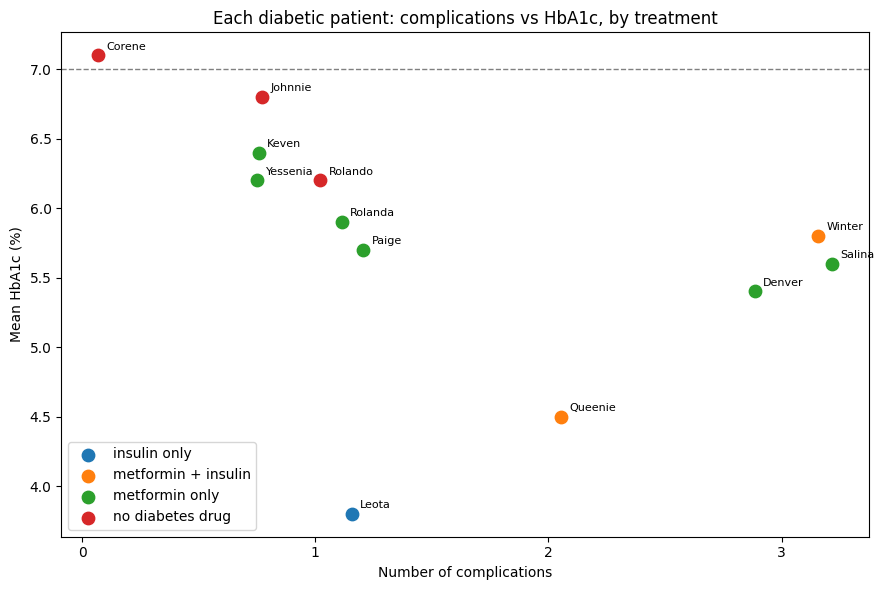

In [18]:
import numpy as np
import matplotlib.pyplot as plt
ps = con.sql("""SELECT FIRST, mean_hba1c, treatment_group, total_complications
                FROM patient_summary ORDER BY FIRST""").df()
ps['x'] = ps.total_complications + np.random.default_rng(0).uniform(-0.25, 0.25, len(ps))
fig, ax = plt.subplots(figsize=(9, 6))
for group, d in ps.groupby('treatment_group'):
    ax.scatter(d.x, d.mean_hba1c, s=80, label=group)
for _, r in ps.iterrows():
    ax.annotate(r.FIRST.rstrip('0123456789'), (r.x, r.mean_hba1c),
                textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.axhline(7, color='grey', linestyle='--', linewidth=1)
ax.set_xticks([0, 1, 2, 3])
ax.set_xlabel('Number of complications')
ax.set_ylabel('Mean HbA1c (%)')
ax.set_title('Each diabetic patient: complications vs HbA1c, by treatment')
ax.legend()
plt.tight_layout()
plt.savefig('patients_scatter.png', dpi=150)
plt.show()

In [19]:
summary = con.sql("""
SELECT treatment_group, COUNT(*) AS patients,
       AVG(mean_hba1c) AS avg_hba1c,
       AVG(obesity) AS obesity, AVG(kidney) AS kidney,
       AVG(neuropathy) AS neuropathy, AVG(retinopathy) AS retinopathy
FROM patient_summary
GROUP BY treatment_group
ORDER BY CASE treatment_group WHEN 'no diabetes drug' THEN 1 WHEN 'metformin only' THEN 2
                              WHEN 'insulin only' THEN 3 ELSE 4 END
""").df()

In [20]:
con.sql("""
CREATE OR REPLACE VIEW latest AS
SELECT PATIENT,
       arg_max(CAST(VALUE AS DOUBLE), CAST(DATE AS DATE)) AS latest_hba1c,
       date_diff('day', MAX(CAST(DATE AS DATE)),
                 (SELECT MAX(CAST(DATE AS DATE)) FROM 'data/observations.csv')) AS days_since_test
FROM 'data/observations.csv'
WHERE CODE = '4548-4'
GROUP BY PATIENT
""")
import pandas as pd
pd.set_option('display.max_colwidth', None)
con.sql("""
SELECT p.FIRST, l.latest_hba1c, l.days_since_test,
  COALESCE(NULLIF(concat_ws('; ',
    CASE WHEN t.on_metformin = 0 AND t.on_insulin = 0 AND l.latest_hba1c >= 6.5
         THEN 'No diabetes drug: start or confirm treatment' END,
    CASE WHEN t.on_insulin = 1 AND l.latest_hba1c < 6.0
         THEN 'Low HbA1c on insulin: review hypoglycemia risk' END,
    CASE WHEN c.kidney = 1
         THEN 'Kidney involvement: eGFR + urine albumin, review drug doses' END,
    CASE WHEN l.days_since_test > 183 THEN 'HbA1c overdue (>6 months)' END
  ), ''), 'Routine follow-up') AS actions
FROM diabetics AS d
JOIN 'data/patients.csv' AS p ON p.Id = d.PATIENT
JOIN treatment AS t ON t.PATIENT = d.PATIENT
JOIN complications AS c ON c.PATIENT = d.PATIENT
JOIN latest AS l ON l.PATIENT = d.PATIENT
WHERE p.DEATHDATE IS NULL
ORDER BY length(actions) DESC
""").df()


,FIRST,latest_hba1c,days_since_test,actions
0,Winter723,5.7,0,"Low HbA1c on insulin: review hypoglycemia risk; Kidney involvement: eGFR + urine albumin, review drug doses"
1,Leota851,3.8,169,"Low HbA1c on insulin: review hypoglycemia risk; Kidney involvement: eGFR + urine albumin, review drug doses"
2,Queenie922,4.5,170,"Low HbA1c on insulin: review hypoglycemia risk; Kidney involvement: eGFR + urine albumin, review drug doses"
3,Rolando809,6.9,160,No diabetes drug: start or confirm treatment
4,Corene694,7.1,112,No diabetes drug: start or confirm treatment
5,Denver542,5.4,207,HbA1c overdue (>6 months)
6,Paige606,5.4,3,Routine follow-up
7,Rolanda823,5.9,76,Routine follow-up
8,Yessenia339,5.7,133,Routine follow-up


In [21]:
con.sql("""
CREATE OR REPLACE VIEW risk_list AS
SELECT p.FIRST, t.on_metformin, t.on_insulin, l.latest_hba1c, l.days_since_test,
       c.obesity, c.kidney, c.neuropathy, c.retinopathy,
       COALESCE(NULLIF(concat_ws('; ',
         CASE WHEN t.on_metformin = 0 AND t.on_insulin = 0 AND l.latest_hba1c >= 6.5
              THEN 'Start or confirm treatment' END,
         CASE WHEN t.on_insulin = 1 AND l.latest_hba1c < 6.0
              THEN 'Review hypoglycemia risk' END,
         CASE WHEN c.kidney = 1 THEN 'Kidney monitoring and dose review' END,
         CASE WHEN l.days_since_test > 183 THEN 'HbA1c overdue' END
       ), ''), 'None') AS urgent_actions,
       concat_ws('; ',
         CASE WHEN c.obesity = 1 THEN 'Weight management' END,
         CASE WHEN c.neuropathy = 1 THEN 'Foot care' END,
         CASE WHEN c.retinopathy = 1 THEN 'Eye follow-up' END
       ) AS ongoing_care
FROM diabetics AS d
JOIN 'data/patients.csv' AS p ON p.Id = d.PATIENT
JOIN treatment AS t ON t.PATIENT = d.PATIENT
JOIN complications AS c ON c.PATIENT = d.PATIENT
JOIN latest AS l ON l.PATIENT = d.PATIENT
WHERE p.DEATHDATE IS NULL
""")
con.sql("SELECT * FROM risk_list ORDER BY urgent_actions = 'None', FIRST").df()

,FIRST,on_metformin,on_insulin,latest_hba1c,days_since_test,obesity,kidney,neuropathy,retinopathy,urgent_actions,ongoing_care
0,Corene694,0,0,7.1,112,0,0,0,0,Start or confirm treatment,
1,Denver542,1,0,5.4,207,1,0,1,1,HbA1c overdue,Weight management; Foot care; Eye follow-up
2,Leota851,0,1,3.8,169,0,1,0,0,Review hypoglycemia risk; Kidney monitoring and dose review,
3,Queenie922,1,1,4.5,170,1,1,0,0,Review hypoglycemia risk; Kidney monitoring and dose review,Weight management
4,Rolando809,0,0,6.9,160,1,0,0,0,Start or confirm treatment,Weight management
5,Winter723,1,1,5.7,0,1,1,1,0,Review hypoglycemia risk; Kidney monitoring and dose review,Weight management; Foot care
6,Paige606,1,0,5.4,3,1,0,0,0,None,Weight management
7,Rolanda823,1,0,5.9,76,1,0,0,0,None,Weight management
8,Yessenia339,1,0,5.7,133,1,0,0,0,None,Weight management


In [22]:
con.sql("""
SELECT COUNT(*) AS living_diabetics,
       CAST(SUM(CASE WHEN urgent_actions <> 'None' THEN 1 ELSE 0 END) AS INTEGER) AS need_urgent_action,
       CAST(SUM(obesity) AS INTEGER) AS obese
FROM risk_list
""").df()

,living_diabetics,need_urgent_action,obese
0,9,6,7


In [23]:
con.sql("""
CREATE OR REPLACE VIEW prevention_list AS
SELECT DISTINCT p.FIRST, l.latest_hba1c, l.days_since_test,
       CASE WHEN c.PATIENT IN (SELECT PATIENT FROM 'data/conditions.csv'
                               WHERE DESCRIPTION ILIKE '%obes%') THEN 1 ELSE 0 END AS obesity
FROM 'data/conditions.csv' AS c
JOIN 'data/patients.csv' AS p ON p.Id = c.PATIENT
JOIN latest AS l ON l.PATIENT = c.PATIENT
WHERE c.DESCRIPTION = 'Prediabetes (finding)'
  AND c.PATIENT NOT IN (SELECT PATIENT FROM diabetics)
  AND p.DEATHDATE IS NULL
""")
con.sql("""SELECT * FROM prevention_list WHERE latest_hba1c >= 6.0
           ORDER BY obesity DESC, latest_hba1c DESC""").df()

,FIRST,latest_hba1c,days_since_test,obesity
0,Andrew29,6.4,278,1
1,Benjamín452,6.3,57,1
2,Erik495,6.3,30,1
3,Robbie31,6.3,363,1
4,Margurite588,6.2,251,1
5,Conchita9,6.2,333,1
6,Lilia791,6.2,262,1
7,Lorenzo669,6.2,369,1
8,Sanora914,6.2,28,1
9,Damien170,6.1,147,1


In [24]:
con.sql("""
SELECT COUNT(*) AS living_prediabetics,
       CAST(SUM(CASE WHEN latest_hba1c >= 6.0 THEN 1 ELSE 0 END) AS INTEGER) AS high_risk_band,
       CAST(SUM(CASE WHEN latest_hba1c >= 6.0 AND obesity = 1 THEN 1 ELSE 0 END) AS INTEGER) AS high_risk_and_obese
FROM prevention_list
""").df()

,living_prediabetics,high_risk_band,high_risk_and_obese
0,31,21,14
